#### Import libraries

In [38]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

#### Load raster layers

In [39]:
base = r"C:\Users\ab\Desktop\Python\data\variables\\"

bathy = rasterio.open(base + "bathymetry.tif").read(1)
slope = rasterio.open(base + "slope.tif").read(1)

print("Bathymetry shape:", bathy.shape)
print("Slope shape:", slope.shape)

Bathymetry shape: (205, 186)
Slope shape: (205, 186)


C:\Users\ab\AppData\Local\Temp\ipykernel_3112\2561731373.py:3: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  bathy = rasterio.open(base + "bathymetry.tif").read(1)
C:\Users\ab\AppData\Local\Temp\ipykernel_3112\2561731373.py:4: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  slope = rasterio.open(base + "slope.tif").read(1)


#### Align remaining rasters

In [40]:
from rasterio.warp import reproject, Resampling

with rasterio.open(base + "bathymetry.tif") as ref:
    ref_array = ref.read(1)
    ref_transform = ref.transform
    ref_crs = ref.crs
    ref_shape = ref_array.shape

def align_to_reference(raster_file):

    with rasterio.open(base + raster_file) as src:

        aligned = np.empty(ref_shape, dtype=np.float32)

        reproject(
            source=src.read(1),
            destination=aligned,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=ref_transform,
            dst_crs=ref_crs,
            resampling=Resampling.nearest
        )

    return aligned

wave = align_to_reference("wave.tif")
light = align_to_reference("light.tif")
substrate = align_to_reference("substrate.tif")

print("Wave:", wave.shape)
print("Light:", light.shape)
print("Substrate:", substrate.shape)

Wave: (205, 186)
Light: (205, 186)
Substrate: (205, 186)


C:\Users\ab\AppData\Local\Temp\ipykernel_3112\3144891007.py:4: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  ref_array = ref.read(1)
C:\Users\ab\AppData\Local\Temp\ipykernel_3112\3144891007.py:16: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  source=src.read(1),
C:\Users\ab\AppData\Local\Temp\ipykernel_3112\3144891007.py:16: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  source=src.read(1),
C:\Users\ab\AppData\Local\Temp\ipykernel_3112\3144891007.py:16: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view u

#### Create a habitat function

In [41]:
import numpy as np

def habitat_model(condition):
    return condition.astype(np.uint8)

#### Create your first habitat (NT-14)

In [42]:
NT14 = habitat_model(
    (bathy >= -30) &
    (bathy <= -1) &
    (slope >= 1) &
    (substrate == 2) &
    (light <= 0.35) &
    (wave >= 2) &
    (wave <= 5)
)

print("NT14 cells:", NT14.sum())

NT14 cells: 48


#### Create a habitat container

In [43]:
habitats = {}

habitats["NT14"] = NT14

print("Habitats stored:", list(habitats.keys()))

Habitats stored: ['NT14']


#### Save NT14 temporarily

In [44]:
import rasterio

with rasterio.open(base + "bathymetry.tif") as ref:
    profile = ref.profile.copy()

profile.update(
    dtype=rasterio.uint8,
    count=1,
    nodata=0
)

with rasterio.open(
    r"C:\Users\ab\Desktop\Python\output\NT14.tif",
    "w",
    **profile
) as dst:

    dst.write(NT14.astype(rasterio.uint8), 1)

print("NT14 saved")


NT14 saved


#### Generate all 21 habitats

In [45]:
habitats = {}

habitats["NT14"] = NT14

print(habitats.keys())

dict_keys(['NT14'])


#### Create the richness framework

In [46]:
richness = np.zeros_like(bathy, dtype=np.uint8)

for h in habitats.values():
    richness += h

print("Maximum richness:", richness.max())


Maximum richness: 1


#### Create all habitat rasters

In [47]:
habitats = {}

# -------------------
# KELP
# -------------------

habitats["NT03"] = habitat_model(
    (bathy >= -2) &
    (bathy <= 0) &
    (slope >= 1) &
    (substrate == 2) &
    (light <= 0.35) &
    (wave >= 2) &
    (wave <= 6)
)

habitats["NT14"] = habitat_model(
    (bathy >= -30) &
    (bathy <= -1) &
    (slope >= 1) &
    (substrate == 2) &
    (light <= 0.35) &
    (wave >= 2) &
    (wave <= 5)
)

habitats["NT16"] = habitat_model(
    (bathy >= -30) &
    (bathy <= -1) &
    (slope >= 2) &
    (substrate == 2) &
    (light <= 0.30) &
    (wave >= 5) &
    (wave <= 8)
)

habitats["NT18"] = habitat_model(
    (bathy >= -15) &
    (bathy <= -1) &
    (slope >= 2) &
    (substrate == 2) &
    (light <= 0.30) &
    (wave >= 4) &
    (wave <= 7)
)

habitats["NT20"] = habitat_model(
    (bathy >= -10) &
    (bathy <= -1) &
    (slope >= 2) &
    (substrate == 2) &
    (light <= 0.30) &
    (wave >= 7)
)

habitats["NT21"] = habitat_model(
    (bathy >= -30) &
    (bathy <= -5) &
    (wave >= 2) &
    (wave <= 6) &
    (light <= 0.35) &
    (slope <= 10)
)

# -------------------
# SEAGRASS
# -------------------

habitats["NT09"] = habitat_model(
    (bathy >= -3) &
    (bathy <= 1) &
    (substrate == 0) &
    (wave <= 4) &
    (slope <= 10)
)

habitats["NT10"] = habitat_model(
    (bathy >= -10) &
    (bathy <= -0.5) &
    (substrate == 0) &
    (wave <= 4) &
    (slope <= 5) &
    (light <= 0.35)
)

habitats["NT11"] = habitat_model(
    (bathy >= -2) &
    (bathy <= 0) &
    (substrate == 0) &
    (wave <= 3) &
    (slope <= 3) &
    (light <= 0.35)
)

habitats["NT13"] = habitat_model(
    (bathy >= -5) &
    (bathy <= 0) &
    (substrate == 0) &
    (wave <= 3) &
    (slope <= 5) &
    (light <= 0.35)
)

habitats["NT32"] = habitat_model(
    (bathy >= -10) &
    (substrate == 0) &
    (wave <= 4) &
    (slope <= 10) &
    (light <= 0.35)
)

# -------------------
# SHELL
# -------------------

habitats["NT02"] = habitat_model(
    (bathy >= -5) &
    (bathy <= 0) &
    (substrate == 2) &
    (wave >= 2) &
    (wave <= 6)
)

habitats["NT07"] = habitat_model(
    (bathy >= -30) &
    (bathy <= -2) &
    (substrate == 0) &
    (wave >= 2)
)

habitats["NT08"] = habitat_model(
    (bathy >= -30) &
    (substrate == 0) &
    (wave >= 4)
)

# -------------------
# TOPOGRAPHY
# -------------------

habitats["NT01"] = habitat_model(
    (bathy >= -1) &
    (bathy <= 1) &
    (substrate == 2) &
    (wave <= 3)
)

habitats["NT04"] = habitat_model(
    (bathy >= -2) &
    (bathy <= 1) &
    (substrate == 2) &
    (slope >= 10)
)

habitats["NT05"] = habitat_model(
    (bathy >= -3) &
    (substrate == 0) &
    (wave <= 4)
)

habitats["NT06"] = habitat_model(
    (bathy >= -15) &
    (substrate == 0)
)

habitats["NT22"] = habitat_model(
    (bathy >= -5) &
    (substrate == 2) &
    (slope >= 10)
)

habitats["NT29"] = habitat_model(
    (bathy <= -2) &
    (substrate == 2) &
    (slope >= 5)
)

habitats["NT30"] = habitat_model(
    (bathy >= -30) &
    (bathy <= 0) &
    (wave >= 7)
)

print("Habitats created:", len(habitats))
print(habitats.keys())


Habitats created: 21
dict_keys(['NT03', 'NT14', 'NT16', 'NT18', 'NT20', 'NT21', 'NT09', 'NT10', 'NT11', 'NT13', 'NT32', 'NT02', 'NT07', 'NT08', 'NT01', 'NT04', 'NT05', 'NT06', 'NT22', 'NT29', 'NT30'])


#### Create the Richness Map

In [48]:
richness = np.zeros_like(bathy, dtype=np.uint8)

for habitat in habitats.values():
    richness += habitat

print("Maximum richness:", richness.max())
print("Mean richness:", richness.mean())

Maximum richness: 6
Mean richness: 0.3998688696564385


#### Visualize Richness Map for 21 Habitats

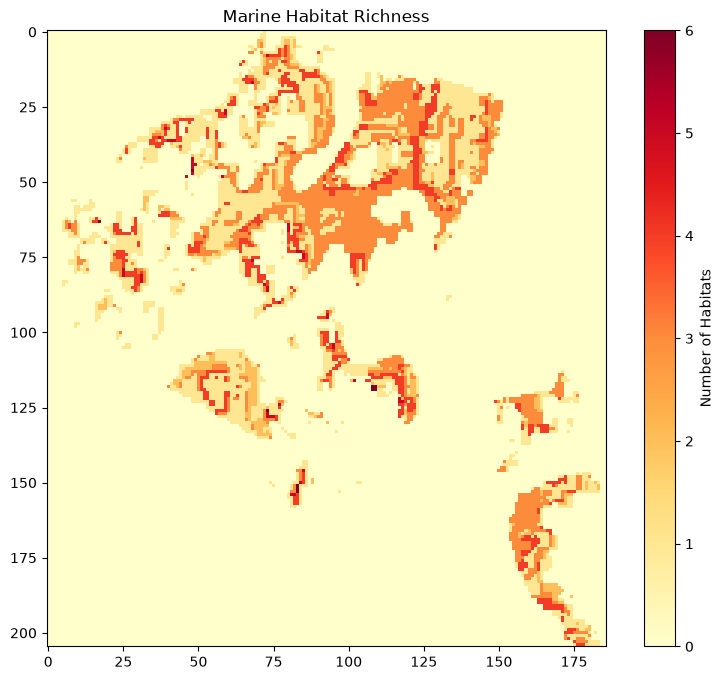

In [49]:
plt.figure(figsize=(10,8))
plt.imshow(richness, cmap="YlOrRd")
plt.colorbar(label="Number of Habitats")
plt.title("Marine Habitat Richness")
plt.show()

#### Save Richness Map

In [50]:
with rasterio.open(base + "bathymetry.tif") as ref:
    profile = ref.profile.copy()

profile.update(
    dtype=rasterio.uint8,
    count=1,
    nodata=0
)

with rasterio.open(
    r"C:\Users\ab\Desktop\Python\output\richness.tif",
    "w",
    **profile
) as dst:

    dst.write(richness.astype(rasterio.uint8), 1)

print("Richness raster saved")


Richness raster saved


#### Save ALL 21 Suitability Maps Automatically

In [51]:
import os

os.makedirs(
    r"C:\Users\ab\Desktop\Python\output\habitats",
    exist_ok=True
)

with rasterio.open(base + "bathymetry.tif") as ref:
    profile = ref.profile.copy()

profile.update(
    dtype=rasterio.uint8,
    count=1,
    nodata=0
)

for name, raster in habitats.items():

    out_file = rf"C:\Users\ab\Desktop\Python\output\habitats\{name}.tif"

    with rasterio.open(
        out_file,
        "w",
        **profile
    ) as dst:

        dst.write(raster.astype(rasterio.uint8), 1)

print("All habitat rasters saved")


All habitat rasters saved


#### Hotspot Analysis from Richness Map

In [52]:
conda install scipy

Jupyter detected...
3 channel Terms of Service accepted
Channels:
 - defaults
Platform: win-64
Solving environment: ...working... done

# All requested packages already installed.


Note: you may need to restart the kernel to use updated packages.


#### Create Hotspot Surface

In [53]:
from scipy.ndimage import generic_filter

local_mean = generic_filter(
    richness.astype(float),
    np.mean,
    size=5
)

local_std = generic_filter(
    richness.astype(float),
    np.std,
    size=5
)

hotspot = np.zeros_like(richness, dtype=float)

mask = local_std > 0

hotspot[mask] = (
    richness[mask] - local_mean[mask]
) / local_std[mask]

print("Hotspot surface created")

Hotspot surface created


#### Display Hotspot Map

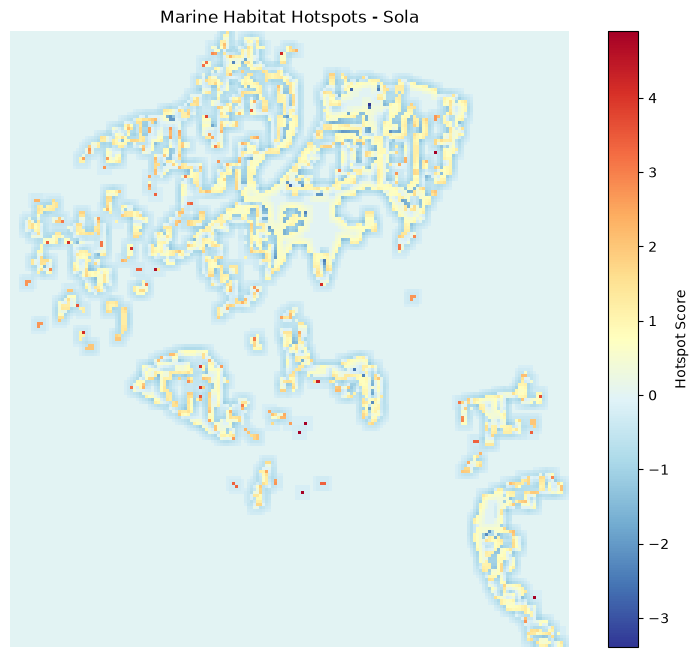

In [54]:
plt.figure(figsize=(10,8))

plt.imshow(
    hotspot,
    cmap="RdYlBu_r"
)

plt.colorbar(label="Hotspot Score")

plt.title("Marine Habitat Hotspots - Sola")

plt.axis("off")

plt.show()

#### Create Classified Hotspot Map

In [55]:
hotspot_class = np.zeros_like(hotspot)

hotspot_class[hotspot >= 2] = 3
hotspot_class[(hotspot >= 1) & (hotspot < 2)] = 2
hotspot_class[(hotspot >= 0.5) & (hotspot < 1)] = 1

hotspot_class[(hotspot <= -0.5) & (hotspot > -1)] = -1
hotspot_class[(hotspot <= -1) & (hotspot > -2)] = -2
hotspot_class[hotspot <= -2] = -3

#### Show Final Hotspot Classes

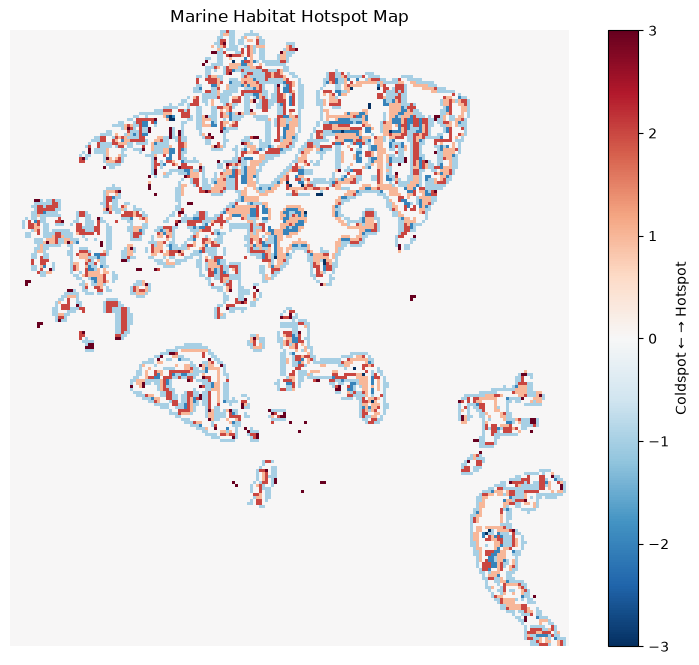

In [56]:
plt.figure(figsize=(10,8))

plt.imshow(
    hotspot_class,
    cmap="RdBu_r",
    vmin=-3,
    vmax=3
)

plt.colorbar(
    label="Coldspot ← → Hotspot"
)

plt.title("Marine Habitat Hotspot Map")

plt.axis("off")

plt.show()

#### Save Hotspot Raster

In [57]:
with rasterio.open(base + "bathymetry.tif") as ref:
    profile = ref.profile.copy()

profile.update(
    dtype=rasterio.int16,
    count=1,
    nodata=0
)

with rasterio.open(
    r"C:\Users\ab\Desktop\Python\output\hotspot_map.tif",
    "w",
    **profile
) as dst:

    dst.write(hotspot_class.astype(np.int16), 1)

print("Hotspot raster saved")


Hotspot raster saved
